# Take-Up Gaps and Administrative Burden — SNAP and the EITC across the States

**Artifact class:** `tutorial`  ·  **Data mode:** `empirical`  ·  **Vintage:** USDA FNS *Reaching Those in Need* (fiscal years 2016, 2017, 2018 and 2022), FNS *State Options Report* (12th and 14th editions) and the IRS EITC participation table (tax years 2014 to 2022)

This notebook uses **real data only**. There is no synthetic generator and no fallback. The state tables exist only inside PDFs, so they are read
from the PDF text by a tested parser (never typed in), and every table is checked for coverage and for agreement with the next report that restates it.

The analysis was fixed in a written plan (`pap/I01_plan.md`) committed before any retrieval, and two amendments, each committed on its own before any result was computed. Both amendments were written after the approved files had been read once for layout (those retrievals are in the run ledger, reconstructed because they left no record) and each followed an owner ruling on a stop-rule that first read triggered. Every provenance record carries the plan and the amendments in force. The notebook says where it departs from the plan.

**This is association across states. It is not the effect of any administrative feature.**

*Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

By the end of this notebook you will be able to:

1. **Define** a take-up gap as the share of eligible people who do not receive a benefit, and say what the participation rate it comes from does and does not contain.
2. **Read** a state table out of a PDF with a parser whose behaviour is tested, and check the result against the next report that restates it.
3. **Estimate** an association between a state's administrative choice and its take-up gap, with an interval from resampling states, and apply a multiple-comparison correction.
4. **Say** why a cross-state association between an administrative feature and take-up does not identify an effect, and name the design that would.

## Prerequisites

**Knowledge.** Rank correlation; a bootstrap that resamples whole units; the idea of a multiple-comparison family.

**Setup.** No key is needed. The notebook downloads six PDFs from the USDA Food and Nutrition Service and one HTML table from the IRS, each recorded in `provenance/`
with the SHA-256 of what was received.

**Packages.** `pandas`, `numpy`, `scipy`, `matplotlib`, `pypdf` (see `DECISIONS/0010`) and the local `krl_tutorials_data` package (`pdf_tables`, `uncertainty`).

**Prior notebooks.** C03 shows the staggered-adoption design that this notebook says would be needed to move from association to effect.

## Data Provenance

| Item | Source | Role |
|---|---|---|
| SNAP participation rates, fiscal years 2016, 2017, 2018, 2022 | USDA FNS, *Reaching Those in Need*, the report for each year | the take-up gap (100 minus the rate) |
| Online application; certification length | USDA FNS, *State Options Report*, 12th edition (options as of 1 October 2015) and 14th edition (as of 1 October 2017), each state's profile page | the two administrative features |
| EITC participation rate by state | IRS, *EITC participation rate by state*, the table on the page | a second take-up gap |
| `data/policy/medicaid/expansion_dates.csv` | repository policy table | the list of 51 jurisdictions (50 states and the District of Columbia) |

> **What a participation rate is.** FNS defines it as the number of people participating divided by the number eligible, estimated from survey and administrative data.
> The later reports cap the rate at 100. The tables printed here carry **no confidence intervals**: the reports show them only in a chart whose text cannot be read, so
> no interval is invented and every gap below is a point estimate.

## Design

**Estimands, all descriptive.**

1. The SNAP take-up gap by state: `100 - participation rate`, in percentage points of eligible people who did not receive SNAP.
2. Its association with two features read from the same state's profile in the options report: whether the state offered an **online application**, and its **certification length**
   (the longest period it uses, in months). The primary year is **fiscal 2018** (options as of 1 October 2017); fiscal 2016 (options as of 1 October 2015) is a replication.
3. The EITC take-up gap and its rank correlation with the SNAP gap.

**Why the options test stops at 2018.** The edition nearest fiscal 2022 within eighteen months has neither feature in its text (the code below checks this and prints what it finds), and the next edition is further than eighteen months away.

**Rules fixed before the data.** The two feature tests in the primary year are one family, corrected by Holm at the level in the configuration cell. The expected direction was written down first:
online application and longer certification go with a **smaller** gap; the SNAP and EITC gaps are **positively** correlated. A null is stated with its interval, never as "no association".

In [1]:
"""Configuration. Every analytic choice is named here, not inferred."""
from __future__ import annotations

import hashlib
import io
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pypdf import PdfReader
from scipy import stats

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src"))
        REPO_ROOT = _cand
        break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data import pdf_tables
from krl_tutorials_data.methods import resample
from krl_tutorials_data.sources import fetch_fns_pdf, fetch_irs_eitc_participation
from krl_tutorials_data.uncertainty import holm_bonferroni

NB_DIR = REPO_ROOT / "projects" / "14-implementation" / "I01_benefit_take_up_administrative_burden"
PLAN = NB_DIR / "pap" / "I01_plan.md"
AMEND = [NB_DIR / "pap" / "I01_plan_amendment_1.md", NB_DIR / "pap" / "I01_plan_amendment_2.md"]
PLAN_SHA256 = hashlib.sha256(PLAN.read_bytes()).hexdigest()

REPORTS = {2016: "resource-files/Reaching2016.pdf", 2017: "resource-files/Reaching2017-1.pdf",
           2018: "resource-files/Reaching2018.pdf", 2022: "resource-files/ear-snap-Reaching-Those-in-Need-2022.pdf"}
EDITIONS = {2016: ("snap/12-State_Options.pdf", "12th edition"), 2018: ("snap/14-State-Options.pdf", "14th edition")}
PRIMARY, REPLICATION, LATEST = 2018, 2016, 2022
ALPHA, N_BOOT, SEED, MAX_MONTHS_APART, MAX_EXCLUDED_DESCRIPTIVE = 0.05, 9999, 20261027, 18, 3
ADDED = "not pre-specified (added after review, 2026-10-27)"

jur = pd.read_csv(REPO_ROOT / "data" / "policy" / "medicaid" / "expansion_dates.csv")["state"].tolist()
if len(jur) != 51 or len(set(jur)) != 51:
    raise SystemExit("expected 51 distinct jurisdictions")
ALIASES = {"DC": "District of Columbia"}

print(f"plan SHA-256         : {PLAN_SHA256}")
for _a in AMEND:
    print(f"{_a.name:26s}: {hashlib.sha256(_a.read_bytes()).hexdigest()}")
print(f"jurisdictions        : {len(jur)}")
print(f"primary / replication: fiscal {PRIMARY} / fiscal {REPLICATION}; descriptive only: fiscal {LATEST}")
print(f"alpha {ALPHA}; bootstrap {N_BOOT:,} draws, seed {SEED}; pairing limit {MAX_MONTHS_APART} months")

plan SHA-256         : 07683027fa91f5525be1fe979fa71252f9d828fd9fd33176833d51b88798d206
I01_plan_amendment_1.md   : 558aa55fe126484bfcc770118bcb2725d2aa298fbdbde60d5678daa76054b51c
I01_plan_amendment_2.md   : bf50dc548aa11e734a5a504a7ec7f5a9335eceb180e60564042c5e757c5a7c2c
jurisdictions        : 51
primary / replication: fiscal 2018 / fiscal 2016; descriptive only: fiscal 2022
alpha 0.05; bootstrap 9,999 draws, seed 20261027; pairing limit 18 months


## Part 1 · Reading the rates out of the PDFs

Each report is downloaded and recorded. The page holding the table is found by its heading; every row must name one of the 51 jurisdictions. Three
repairs, all stated in the amendment and all printed when they happen: a name split across lines, a number split in two, and nothing else. A row that
cannot be read is excluded and named, never filled.

In [2]:
"""Download the four reports and read each state table twice."""
def table_page(pages, fy):
    """The page carrying the heading 'Estimates of participation rates' and the most jurisdiction rows.

    The heading phrase also occurs in running text on other pages, so the pages that carry it are ranked
    by how many distinct jurisdictions they have as rows; a page needs at least 40, and the best must stand alone.
    """
    hits = pdf_tables.find_pages(pages, "Estimates of participation rates")
    score = {}
    for i in hits:
        lines, _ = pdf_tables.repair_split_names(pages[i].splitlines(), jur)
        score[i] = len({r.name for r in pdf_tables.parse_jurisdiction_rows(lines, jur).rows})
    ranked = sorted(score.items(), key=lambda kv: -kv[1])
    if not ranked or ranked[0][1] < 40 or (len(ranked) > 1 and ranked[1][1] >= 40):
        raise SystemExit(f"fiscal {fy}: no single table page; heading pages and their row counts {score}")
    return ranked[0][0]


def years_header(lines, fy, k):
    """The printed column years; the report's own year must be the last of the first k."""
    for line in lines:
        years = [int(y) for y in re.findall(r"\b(20\d\d)\b", line)]
        if len(years) >= k and all(2000 <= y <= 2030 for y in years) and re.fullmatch(r"[\sA-Za-z0-9]*", line):
            if years[k - 1] != fy:
                raise SystemExit(f"fiscal {fy}: header {line!r} does not end the first {k} columns in {fy}")
            return years[:k], line.strip()
    raise SystemExit(f"fiscal {fy}: no column-year header found")


def read_rates(body: bytes, fy: int):
    """Return (series, log) for one report: the rate for the report's own fiscal year by jurisdiction."""
    k, expected = (3, 6) if fy <= 2019 else (2, 2)
    pages = [p.extract_text() or "" for p in PdfReader(io.BytesIO(body)).pages]
    page = table_page(pages, fy)
    lines = pages[page].splitlines()
    lines, joins = pdf_tables.repair_split_names(lines, jur)
    start = next(i for i, l in enumerate(lines) if "Estimates of participation rates" in l)
    years, header = years_header(lines[start:start + 6], fy, k)
    parsed = pdf_tables.parse_jurisdiction_rows(lines[start:], jur)
    counts = pd.Series([len(r.values) for r in parsed.rows]).value_counts()
    modal = int(counts.idxmax())
    values, merges, excluded = {}, [], []
    for r in parsed.rows:
        got = pdf_tables.reconcile_row(r, expected=modal, max_value=100.0)
        if got is None:
            excluded.append(r.name)
            continue
        if len(r.values) != modal:
            merges.append((r.name, r.values, got))
        if r.name in values:
            raise SystemExit(f"fiscal {fy}: {r.name} appears twice")
        values[r.name] = got[k - 1]
    # the same table read from the whole document's text must agree with the page-by-page read
    whole = "\n".join(pages).splitlines()
    whole, _ = pdf_tables.repair_split_names(whole, jur)
    again = {}
    for r in pdf_tables.parse_jurisdiction_rows(whole, jur).rows:
        got = pdf_tables.reconcile_row(r, expected=modal, max_value=100.0)
        if got is not None and r.name in values and r.name not in again:
            again[r.name] = got[k - 1]
    agree = all(again.get(n) == v for n, v in values.items())
    return pd.Series(values, name=f"rate_{fy}"), {
        "page": page, "header": header, "years": years, "modal": modal, "joins": joins, "merges": merges,
        "excluded": excluded, "rejected": len(parsed.rejected), "reread_agrees": agree}


rates, logs = {}, {}
for fy, path in REPORTS.items():
    body, prov = fetch_fns_pdf(path=path, vintage=f"fiscal year {fy}")
    prov.with_pap_chain(PLAN, *AMEND).write(NB_DIR / "provenance" / f"i01_fns_reaching_{fy}.json")
    rates[fy], logs[fy] = read_rates(body, fy)
    lg = logs[fy]
    print(f"fiscal {fy}: {len(body):,} bytes, digest {prov.content_sha256[:12]}; table on page {lg['page'] + 1}; header '{lg['header']}'")
    print(f"   rows read {len(rates[fy])} of {len(jur)}; name joins {len(lg['joins'])}; number merges {len(lg['merges'])}; excluded {lg['excluded'] or 'none'}; unparsed lines after a name {lg['rejected']}")
    for j in lg["joins"]:
        print(f"   joined {j[1]!r} + {j[2]!r}")
    for name, before, after in lg["merges"]:
        print(f"   merged in {name}: {tuple(int(v) for v in before)} -> {tuple(int(v) for v in after)}")
    print(f"   whole-document read agrees with the page-by-page read: {lg['reread_agrees']}")

fiscal 2016: 647,644 bytes, digest de54239d9c1a; table on page 5; header '2014      2015    2016 2014         2015 2016'
   rows read 51 of 51; name joins 0; number merges 0; excluded none; unparsed lines after a name 0
   whole-document read agrees with the page-by-page read: True


fiscal 2017: 1,134,902 bytes, digest c03ce0190e78; table on page 5; header '2015      2016    2017 2015         2016 2017'
   rows read 51 of 51; name joins 0; number merges 0; excluded none; unparsed lines after a name 0
   whole-document read agrees with the page-by-page read: True


fiscal 2018: 1,428,103 bytes, digest b7b8f5e89898; table on page 5; header '2016      2017    2018 2016         2017 2018'
   rows read 51 of 51; name joins 2; number merges 1; excluded none; unparsed lines after a name 0
   joined 'L' + 'ouisiana 82 86 83 74 74 73'
   joined 'O' + 'regon 100 100 100 91 96 88'
   merged in Oklahoma: (80, 83, 85, 71, 7, 6, 78) -> (80, 83, 85, 71, 76, 78)
   whole-document read agrees with the page-by-page read: True


fiscal 2022: 900,600 bytes, digest 2aec9d73abbd; table on page 4; header 'State 2020 2022'
   rows read 50 of 51; name joins 0; number merges 0; excluded ['California']; unparsed lines after a name 0
   whole-document read agrees with the page-by-page read: True


In [3]:
"""Coverage rule from the plan and amendment: 51 of 51 for the association years; up to the stated number excluded for the descriptive year."""
cov_ok = True
for fy in (PRIMARY, REPLICATION):
    missing = [n for n in jur if n not in rates[fy].index]
    ok = not missing
    cov_ok &= ok
    print(f"FALSIFICATION: coverage_{fy} statistic={len(rates[fy])} of {len(jur)} jurisdictions read; missing {missing or 'none'} verdict={'PASS' if ok else 'FAIL'}")
miss22 = [n for n in jur if n not in rates[LATEST].index]
ok22 = len(miss22) <= MAX_EXCLUDED_DESCRIPTIVE
print(f"FALSIFICATION: coverage_{LATEST} statistic={len(rates[LATEST])} of {len(jur)} jurisdictions read; excluded {miss22 or 'none'}; at most {MAX_EXCLUDED_DESCRIPTIVE} allowed for a descriptive year verdict={'PASS' if ok22 else 'FAIL'}")
rng_ok = all(((r >= 0) & (r <= 100)).all() for r in rates.values())
n100 = {fy: int((r == 100).sum()) for fy, r in rates.items()}
print(f"FALSIFICATION: range statistic={max(r.max() for r in rates.values()):.0f} largest rate read; every rate between 0 and 100 verdict={'PASS' if rng_ok else 'FAIL'}")
print("states at the cap of 100 percent: " + ", ".join(f"fiscal {fy}: {n}" for fy, n in n100.items()))
reread = all(lg["reread_agrees"] for lg in logs.values())
print(f"FALSIFICATION: reread statistic={int(reread)} the whole-document read gives the same table as the page-by-page read in every report verdict={'PASS' if reread else 'FAIL'}")
if not (cov_ok and ok22 and rng_ok and reread):
    raise SystemExit("a coverage, range or re-read rule failed; ask the owner")

FALSIFICATION: coverage_2018 statistic=51 of 51 jurisdictions read; missing none verdict=PASS
FALSIFICATION: coverage_2016 statistic=51 of 51 jurisdictions read; missing none verdict=PASS
FALSIFICATION: coverage_2022 statistic=50 of 51 jurisdictions read; excluded ['California']; at most 3 allowed for a descriptive year verdict=PASS
FALSIFICATION: range statistic=100 largest rate read; every rate between 0 and 100 verdict=PASS
states at the cap of 100 percent: fiscal 2016: 7, fiscal 2017: 6, fiscal 2018: 3, fiscal 2022: 11
FALSIFICATION: reread statistic=1 the whole-document read gives the same table as the page-by-page read in every report verdict=PASS


### A check against the next report

Each report restates the two earlier years it covers (the later report's estimates can differ because the method is updated). If the parser were reading the wrong column,
the restated values would not resemble the original ones. The comparison below is for fiscal 2016 and 2017, each as the fiscal 2018 report prints them against the report for that year.

In [4]:
"""Fiscal 2018's report restates 2016 and 2017: compare those columns with the reports for those years."""
body18, _ = fetch_fns_pdf(path=REPORTS[2018], vintage="fiscal year 2018")
pages18 = [p.extract_text() or "" for p in PdfReader(io.BytesIO(body18)).pages]
lines18, _ = pdf_tables.repair_split_names(pages18[logs[2018]["page"]].splitlines(), jur)
rows18 = {}
for r in pdf_tables.parse_jurisdiction_rows(lines18, jur).rows:
    got = pdf_tables.reconcile_row(r, expected=logs[2018]["modal"], max_value=100.0)
    if got is not None:
        rows18[r.name] = got[:3]
restated = {2016: pd.Series({n: v[0] for n, v in rows18.items()}), 2017: pd.Series({n: v[1] for n, v in rows18.items()})}
for fy in (2016, 2017):
    both = pd.concat([rates[fy], restated[fy]], axis=1, join="inner")
    d = (both.iloc[:, 1] - both.iloc[:, 0])
    print(f"fiscal {fy}: report for that year vs the fiscal 2018 report's restatement, {len(both)} states: "
          f"mean difference {d.mean():+.1f} points, mean absolute difference {d.abs().mean():.1f}, largest {d.abs().max():.0f}; correlation {both.corr().iloc[0, 1]:.3f}")
    c = both.corr().iloc[0, 1]
    print(f"FALSIFICATION: restated_{fy} statistic={c:.3f} correlation between the two readings of the same year; a column read wrongly would not correlate above 0.8 verdict={'PASS' if c > 0.8 else 'FAIL'}")

fiscal 2016: report for that year vs the fiscal 2018 report's restatement, 51 states: mean difference -2.5 points, mean absolute difference 3.3, largest 11; correlation 0.936
FALSIFICATION: restated_2016 statistic=0.936 correlation between the two readings of the same year; a column read wrongly would not correlate above 0.8 verdict=PASS
fiscal 2017: report for that year vs the fiscal 2018 report's restatement, 51 states: mean difference -2.5 points, mean absolute difference 3.0, largest 13; correlation 0.959
FALSIFICATION: restated_2017 statistic=0.959 correlation between the two readings of the same year; a column read wrongly would not correlate above 0.8 verdict=PASS


## Part 2 · The administrative features

Each state's profile page in the options report carries the same labelled lines. The pages are found by a jurisdiction named in their first lines and the label `Online Application`; the
values are read by label. The edition's "as of" date is read from its text and the distance to the start of the fiscal year is printed.

In [5]:
"""Read the options reports' state profiles."""
LABELS = {"online": r"Online\s+Application", "length": r"Certification\s+Length"}
feat, asof = {}, {}
for fy, (path, name) in EDITIONS.items():
    body, prov = fetch_fns_pdf(path=path, vintage=f"State Options Report, {name}")
    prov.with_pap_chain(PLAN, *AMEND).write(NB_DIR / "provenance" / f"i01_fns_options_{fy}.json")
    pages = [p.extract_text() or "" for p in PdfReader(io.BytesIO(body)).pages]
    m = re.search(r"as\s*of\s*October\s*1,\s*(\d{4})", " ".join(pages[:8]), re.I)
    if not m:
        raise SystemExit(f"{name}: no options date found")
    months = abs((fy - 1) - int(m.group(1))) * 12
    asof[fy] = (int(m.group(1)), months)
    profs, assigned = pdf_tables.parse_profiles_with_contents(pages, jur, LABELS, ALIASES)
    for a in assigned:
        print(f"   assigned by page number (amendment 2): {a.name} <- PDF page {a.page + 1}, printed footer {a.footer}, contents entry {a.contents}")
    seen = pd.Series([p.name for p in profs]).value_counts()
    missing = [n for n in jur if n not in seen.index]
    dup = seen[seen > 1].index.tolist()
    nolabel = [p.name for p in profs if p.fields["online"] is None or p.fields["length"] is None]
    ok = not missing and not dup and not nolabel
    print(f"{name} ({len(pages)} pages, digest {prov.content_sha256[:12]}): options as of 1 October {asof[fy][0]}; {asof[fy][1]} months from the start of fiscal {fy}")
    print(f"   profiles found for {len(seen)} jurisdictions; missing {missing or 'none'}; repeated {dup or 'none'}; missing a label {nolabel or 'none'}")
    print(f"FALSIFICATION: profiles_{fy} statistic={len(seen)} jurisdictions with exactly one profile carrying both labels; need {len(jur)} verdict={'PASS' if ok else 'FAIL'}")
    if not ok or asof[fy][1] > MAX_MONTHS_APART:
        raise SystemExit(f"{name}: profile coverage or pairing distance failed; ask the owner")
    df = pd.DataFrame([{"state": p.name, "online_text": p.fields["online"], "length_text": p.fields["length"]} for p in profs]).set_index("state").loc[jur]
    df["online"] = df["online_text"].map(pdf_tables.online_offered)
    df["months"] = df["length_text"].map(pdf_tables.longest_months)
    feat[fy] = df
    print("   online application values: " + "; ".join(f"{v}: {n}" for v, n in df["online_text"].value_counts().items()))
    print(f"   offered online application (coded 1): {int(df['online'].sum())} of {len(df)}; certification length missing for {df.index[df['months'].isna()].tolist() or 'none'}")
    print(f"   longest certification period, months: " + ", ".join(f"{int(k)}: {int(n)}" for k, n in df["months"].value_counts().sort_index().items()))

12th edition (82 pages, digest 3fe71ad37b86): options as of 1 October 2015; 0 months from the start of fiscal 2016
   profiles found for 51 jurisdictions; missing none; repeated none; missing a label none
FALSIFICATION: profiles_2016 statistic=51 jurisdictions with exactly one profile carrying both labels; need 51 verdict=PASS
   online application values: Apply & recertify: 29; Apply: 14; No online application: 7; Recertify: 1
   offered online application (coded 1): 43 of 51; certification length missing for none
   longest certification period, months: 6: 6, 12: 23, 24: 22


   assigned by page number (amendment 2): Virginia <- PDF page 88, printed footer 82, contents entry 82
14th edition (93 pages, digest 31dc7ac21741): options as of 1 October 2017; 0 months from the start of fiscal 2018
   profiles found for 51 jurisdictions; missing none; repeated none; missing a label none
FALSIFICATION: profiles_2018 statistic=51 jurisdictions with exactly one profile carrying both labels; need 51 verdict=PASS
   online application values: Apply & recertify: 32; Apply: 12; No online application: 5; Apply only: 2
   offered online application (coded 1): 46 of 51; certification length missing for ['Maine']
   longest certification period, months: 6: 5, 12: 21, 24: 24


### Why the options test cannot be run for fiscal 2022

The plan paired each fiscal year with the edition whose date is nearest, within eighteen months. For fiscal 2022 that is the 15th edition (options as of 1 October 2022). The cell below
looks for the two features in its text and in the 17th edition's; it reports what it finds and does not substitute anything.

In [6]:
"""Do the editions near fiscal 2022 carry the two features at all?"""
for path, name, asof_year in [("resource-files/snap-15th-state-options-report-october23.pdf", "15th edition", 2022),
                              ("resource-files/snap-stateOptionsReport-17edition-120925.pdf", "17th edition", 2024)]:
    body, prov = fetch_fns_pdf(path=path, vintage=f"State Options Report, {name}")
    prov.with_pap_chain(PLAN, *AMEND).write(NB_DIR / "provenance" / f"i01_fns_options_{name[:2]}th.json")
    pages = [p.extract_text() or "" for p in PdfReader(io.BytesIO(body)).pages]
    text = "\n".join(pages)
    on = len(re.findall(r"Online\s+Applications?", text, re.I))
    ln = len(re.findall(r"Certification\s+Length", text, re.I))
    months = abs((LATEST - 1) - asof_year) * 12
    print(f"{name}: options as of 1 October {asof_year} ({months} months from the start of fiscal {LATEST}); text mentions 'Online Application' {on} times and 'Certification Length' {ln} times")
print(f"so for fiscal {LATEST} the options test is not possible with the approved files: the edition within {MAX_MONTHS_APART} months has no online-application or certification-length line, and the other is further away")

15th edition: options as of 1 October 2022 (12 months from the start of fiscal 2022); text mentions 'Online Application' 0 times and 'Certification Length' 0 times


17th edition: options as of 1 October 2024 (36 months from the start of fiscal 2022); text mentions 'Online Application' 0 times and 'Certification Length' 0 times
so for fiscal 2022 the options test is not possible with the approved files: the edition within 18 months has no online-application or certification-length line, and the other is further away


## Part 3 · The take-up gap by state

In [7]:
gap = {fy: 100.0 - r for fy, r in rates.items()}
for fy in (PRIMARY, REPLICATION, LATEST):
    g = gap[fy]
    print(f"fiscal {fy}: gap (points of eligible people not participating), {len(g)} jurisdictions: mean {g.mean():.1f}, median {g.median():.1f}; "
          f"largest {g.idxmax()} {g.max():.0f}, smallest {g.idxmin()} {g.min():.0f}; {int((g == 0).sum())} at zero")
print("The gap is not weighted by population: the unit is the state.")
print(f"largest five gaps in fiscal {PRIMARY}: " + ", ".join(f"{n} {v:.0f}" for n, v in gap[PRIMARY].sort_values(ascending=False).head(5).items()))

fiscal 2018: gap (points of eligible people not participating), 51 jurisdictions: mean 17.1, median 17.0; largest Wyoming 46, smallest Delaware 0; 3 at zero
fiscal 2016: gap (points of eligible people not participating), 51 jurisdictions: mean 14.6, median 15.0; largest Wyoming 44, smallest Illinois 0; 7 at zero
fiscal 2022: gap (points of eligible people not participating), 50 jurisdictions: mean 11.3, median 8.5; largest Arkansas 41, smallest District of Columbia 0; 11 at zero
The gap is not weighted by population: the unit is the state.
largest five gaps in fiscal 2018: Wyoming 46, North Dakota 37, Arkansas 34, Kansas 32, North Carolina 31


## Part 4 · Association with the two features

For each year the dependent quantity is the state's gap. The online-application contrast is the difference in mean gap between states that offered it and states that did not, with a 95% interval from resampling
states within each group. The certification-length association is Spearman's rank correlation with a 95% interval from resampling states. The two tests in the primary year form one family under Holm.

In [8]:
"""Association tests with state bootstraps."""

def association(fy):
    """Both tests for one fiscal year; returns a dict of results."""
    d = pd.concat([gap[fy].rename("gap"), feat[fy][["online", "months"]]], axis=1, join="inner")
    y, g = d["gap"].to_numpy(), d["online"].to_numpy()
    diff = y[g == 1].mean() - y[g == 0].mean()
    bd = resample.bootstrap_mean_difference(y, g, draws=N_BOOT, seed=SEED)
    p_mw = stats.mannwhitneyu(y[g == 1], y[g == 0], alternative="two-sided").pvalue
    m = d.dropna(subset=["months"])
    rho, p_rho = stats.spearmanr(m["months"], m["gap"])
    br = resample.bootstrap_spearman(m["months"].to_numpy(), m["gap"].to_numpy(), draws=N_BOOT, seed=SEED)
    return {"n": len(d), "n_online": int(g.sum()), "n_no": int((g == 0).sum()), "diff": diff, "diff_ci": tuple(np.percentile(bd, [2.5, 97.5])),
            "p_mw": p_mw, "n_m": len(m), "rho": float(rho), "rho_ci": tuple(np.percentile(br, [2.5, 97.5])), "p_rho": float(p_rho)}


res = {fy: association(fy) for fy in (PRIMARY, REPLICATION)}
for fy, r in res.items():
    tag = "primary" if fy == PRIMARY else "replication (not corrected, not pooled)"
    print(f"=== fiscal {fy}, {tag}")
    print(f"online application: {r['n_online']} states with it, {r['n_no']} without; mean gap difference (with minus without) {r['diff']:+.2f} points, 95% state-bootstrap interval {r['diff_ci'][0]:+.2f} to {r['diff_ci'][1]:+.2f}; Mann-Whitney p = {r['p_mw']:.3f}")
    print(f"certification length: {r['n_m']} states with a length; Spearman rho {r['rho']:+.3f}, 95% state-bootstrap interval {r['rho_ci'][0]:+.3f} to {r['rho_ci'][1]:+.3f}; p = {r['p_rho']:.3f}")

=== fiscal 2018, primary
online application: 46 states with it, 5 without; mean gap difference (with minus without) -4.08 points, 95% state-bootstrap interval -17.17 to +5.14; Mann-Whitney p = 0.800
certification length: 50 states with a length; Spearman rho -0.137, 95% state-bootstrap interval -0.397 to +0.136; p = 0.342
=== fiscal 2016, replication (not corrected, not pooled)
online application: 43 states with it, 8 without; mean gap difference (with minus without) -3.92 points, 95% state-bootstrap interval -13.58 to +4.51; Mann-Whitney p = 0.551
certification length: 51 states with a length; Spearman rho -0.088, 95% state-bootstrap interval -0.358 to +0.204; p = 0.539


In [9]:
"""The primary-year family, corrected, and the reading each result gets under the rule fixed before the data."""
p = np.array([res[PRIMARY]["p_mw"], res[PRIMARY]["p_rho"]])
corr = holm_bonferroni(p, alpha=ALPHA)
print(corr.render())
print(f"rejected after correction: online application {bool(corr.rejected[0])}, certification length {bool(corr.rejected[1])}")
r = res[PRIMARY]
lo, hi = r["diff_ci"]
print("online application, fiscal " + str(PRIMARY) + ": " + (f"the interval {lo:+.2f} to {hi:+.2f} points excludes zero" if lo > 0 or hi < 0 else f"not distinguishable from zero: the interval is {lo:+.2f} to {hi:+.2f} points"))
lo, hi = r["rho_ci"]
print("certification length, fiscal " + str(PRIMARY) + ": " + (f"the interval {lo:+.3f} to {hi:+.3f} excludes zero" if lo > 0 or hi < 0 else f"not distinguishable from zero: the interval is {lo:+.3f} to {hi:+.3f}"))
exp = (res[PRIMARY]["diff"] < 0, res[PRIMARY]["rho"] < 0)
print(f"expected direction (smaller gap with online application; smaller gap with longer certification): online {'as expected' if exp[0] else 'opposite'}, length {'as expected' if exp[1] else 'opposite'}")
for fy in (PRIMARY, REPLICATION):
    rr = res[fy]
    print(f"FALSIFICATION: direction_{fy} statistic={rr['diff']:+.2f} points, online-application gap difference; expected below zero verdict={'PASS' if rr['diff'] < 0 else 'FAIL'}")

Holm-Bonferroni (FWER) at alpha = 0.05 over 2 tests: 0 significant uncorrected -> 0 after correction (0 withdrawn).
rejected after correction: online application False, certification length False
online application, fiscal 2018: not distinguishable from zero: the interval is -17.17 to +5.14 points
certification length, fiscal 2018: not distinguishable from zero: the interval is -0.397 to +0.136
expected direction (smaller gap with online application; smaller gap with longer certification): online as expected, length as expected
FALSIFICATION: direction_2018 statistic=-4.08 points, online-application gap difference; expected below zero verdict=PASS
FALSIFICATION: direction_2016 statistic=-3.92 points, online-application gap difference; expected below zero verdict=PASS


### Reading the results

The words in the plan are used as written. An association that survives the correction in the primary year is called *suggested by the data*; one whose interval contains zero is
*not distinguishable from zero*, with the interval above. With fifty-one states in one year, neither can say what would happen to a state's take-up if it changed its practice: states that adopt
online applications or longer certification periods differ in income, caseload, administrative capacity and politics, none of which is modelled here.

**What would identify an effect.** A design with variation in timing: states adopting a feature in different years, observed before and after, with an event-study and a test of pre-trends, in the
form of C03's staggered-adoption analysis. That needs state-by-year participation estimates and adoption dates, neither of which this notebook has.

## Part 5 · The EITC

In [10]:
"""EITC participation by state, and its rank correlation with the SNAP gap in the same calendar year."""
eitc, eprov = fetch_irs_eitc_participation()
eprov.with_pap_chain(PLAN, *AMEND).write(NB_DIR / "provenance" / "i01_irs_eitc_participation.json")
eitc = eitc[~eitc["state"].str.startswith("National")].set_index("state")
if set(eitc.index) != set(jur):
    raise SystemExit("IRS table does not name exactly the 51 jurisdictions")
print(f"IRS table: {len(eitc)} jurisdictions, tax years {', '.join(c.split()[-1] for c in eitc.columns)}; digest {eprov.content_sha256[:12]}")
eres = {}
for fy in (PRIMARY, REPLICATION, LATEST):
    eg = (100.0 - eitc[f"Tax year {fy}"]).rename("eitc_gap")
    d = pd.concat([gap[fy].rename("snap_gap"), eg], axis=1, join="inner").dropna()
    rho, pv = stats.spearmanr(d["snap_gap"], d["eitc_gap"])
    br = resample.bootstrap_spearman(d["snap_gap"].to_numpy(), d["eitc_gap"].to_numpy(), draws=N_BOOT, seed=SEED)
    lo, hi = np.percentile(br, [2.5, 97.5])
    eres[fy] = (float(rho), float(lo), float(hi), float(pv), len(d))
    print(f"fiscal {fy} SNAP gap vs tax year {fy} EITC gap, {len(d)} jurisdictions: Spearman rho {rho:+.3f}, 95% state-bootstrap interval {lo:+.3f} to {hi:+.3f}; p = {pv:.3f}")
print("A fiscal year (October to September) and a tax year do not coincide; they are matched by the calendar year in which the fiscal year ends, and they overlap.")
print("These three correlations are descriptive and are not in the corrected family.")
exp_ok = eres[PRIMARY][0] > 0
lo_e, hi_e = eres[PRIMARY][1], eres[PRIMARY][2]
print(f"reading, fiscal {PRIMARY}: the SNAP and EITC gaps are " + ("positively correlated, as expected" if lo_e > 0 else f"not distinguishable from zero (interval {lo_e:+.3f} to {hi_e:+.3f}); the expected positive sign was not found in the primary year"))
print(f"FALSIFICATION: direction_eitc statistic={eres[PRIMARY][0]:+.3f} Spearman correlation of the SNAP and EITC gaps in the primary year; expected positive verdict={'PASS' if exp_ok else 'FAIL'}")

IRS table: 51 jurisdictions, tax years 2022, 2021, 2020, 2019, 2018, 2017, 2016, 2015, 2014; digest e23329d8a870


fiscal 2018 SNAP gap vs tax year 2018 EITC gap, 51 jurisdictions: Spearman rho -0.024, 95% state-bootstrap interval -0.293 to +0.253; p = 0.870


fiscal 2016 SNAP gap vs tax year 2016 EITC gap, 51 jurisdictions: Spearman rho +0.260, 95% state-bootstrap interval -0.051 to +0.533; p = 0.065


fiscal 2022 SNAP gap vs tax year 2022 EITC gap, 50 jurisdictions: Spearman rho +0.172, 95% state-bootstrap interval -0.134 to +0.459; p = 0.232
A fiscal year (October to September) and a tax year do not coincide; they are matched by the calendar year in which the fiscal year ends, and they overlap.
These three correlations are descriptive and are not in the corrected family.
reading, fiscal 2018: the SNAP and EITC gaps are not distinguishable from zero (interval -0.293 to +0.253); the expected positive sign was not found in the primary year
FALSIFICATION: direction_eitc statistic=-0.024 Spearman correlation of the SNAP and EITC gaps in the primary year; expected positive verdict=FAIL


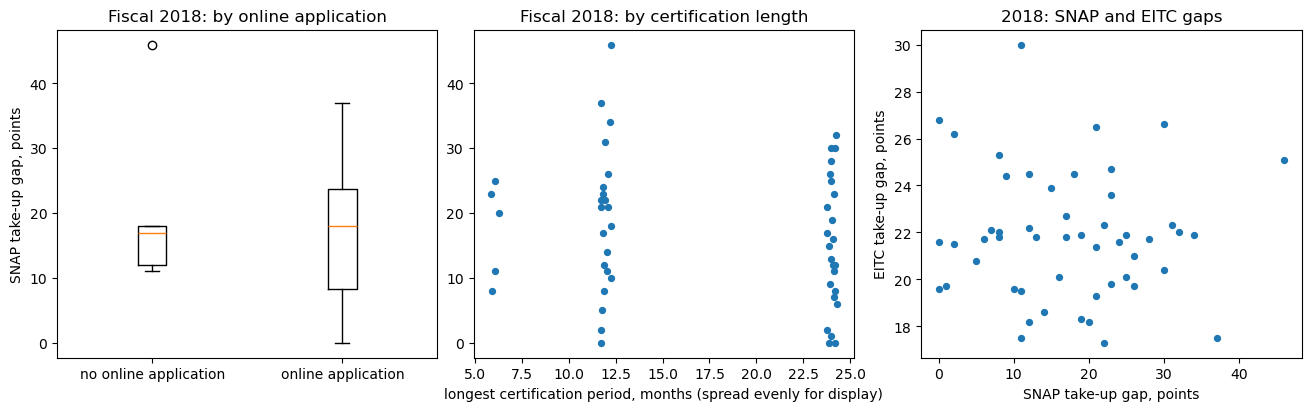

Left: SNAP gap by whether the state offered an online application. Middle: SNAP gap by certification length. Right: SNAP gap against EITC gap. Each point is a state; no point has an interval because the reports print none.


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
d = pd.concat([gap[PRIMARY].rename("gap"), feat[PRIMARY][["online", "months"]]], axis=1)
axes[0].boxplot([d.loc[d["online"] == 0, "gap"], d.loc[d["online"] == 1, "gap"]], tick_labels=["no online application", "online application"])
axes[0].set_ylabel("SNAP take-up gap, points"); axes[0].set_title(f"Fiscal {PRIMARY}: by online application")
axes[1].scatter(d["months"] + ((np.arange(len(d)) * 0.618034) % 1.0 - 0.5) * 0.6, d["gap"], s=18)
axes[1].set_xlabel("longest certification period, months (spread evenly for display)"); axes[1].set_title(f"Fiscal {PRIMARY}: by certification length")
e = pd.concat([gap[PRIMARY].rename("snap"), (100 - eitc[f"Tax year {PRIMARY}"]).rename("eitc")], axis=1)
axes[2].scatter(e["snap"], e["eitc"], s=18); axes[2].set_xlabel("SNAP take-up gap, points"); axes[2].set_ylabel("EITC take-up gap, points"); axes[2].set_title(f"{PRIMARY}: SNAP and EITC gaps")
plt.show()
print("Left: SNAP gap by whether the state offered an online application. Middle: SNAP gap by certification length. Right: SNAP gap against EITC gap. Each point is a state; no point has an interval because the reports print none.")

## Limitations

- **Association only, across at most fifty-one states.** States that adopt online applications or longer certification periods differ in many ways the notebook does not model; no effect of a feature is estimated, and the text refuses that reading.
- **The options can be tested in two fiscal years only.** The approved editions that carry both features are the 12th and the 14th, which pair with fiscal 2016 and fiscal 2018. For fiscal 2022 the edition within eighteen months has neither feature in its text, so the test is not possible there. This is a narrower test than the plan's primary year, by amendment.
- **No intervals on the gaps.** The reports print confidence intervals only in a chart whose text layer cannot be read, so each gap is a point estimate and the bootstrap intervals describe only the sampling of states, not the error in each state's rate.
- **The rates are FNS's estimates**, from survey and administrative data with their own error, which this notebook does not re-derive; the later reports cap rates at 100, so a state at the cap has a gap of zero that may understate its true gap.
- **Timing.** A fiscal year runs October to September and an options report is dated 1 October of a year; the pairing is exact in the primary and replication years, but the EITC is a tax-year estimate for a different benefit, matched by calendar year, and overlaps without coinciding.
- **Two features, coded by rule.** Certification length is the longest period a state uses; a state with a shorter period too is coded by its longest. "Recertify" only is coded as no online application. Neither is a complete measure of administrative burden.
- **PDF text extraction is a parse, not proof.** It is checked by a coverage rule, a range check, a second read and the agreement of restated years, and three repairs (a name split across lines, a number split in two, and exclusion of an unreadable row) are printed when they occur. A table that read cleanly may still hold an error these checks cannot see.
- **Unweighted.** The gap is not weighted by population; the unit is the state.
- **Departures from the plan.** The plan was not edited. Amendment 1 narrowed the years in which the options are tested, allowed the three repairs, and fixed how the features are coded, all after reading the files for layout and before any gap or association was computed. Whether that reading influenced the choice of years is for the reader to weigh.

## Key Takeaways

1. A take-up gap is the share of eligible people who do not receive a benefit; it depends entirely on how "eligible" was estimated, so it carries that estimate's error even when no interval is printed.
2. Tables that exist only in a PDF can be read by a parser, but a parse is a claim to be checked: coverage, range, a second read and the agreement of years that two reports both print.
3. An association across states between an administrative feature and take-up is a description. The design that would support an effect needs variation in timing within states and a test of pre-trends.
4. When the data that would test an hypothesis are missing for the year you care about, say so and test where you can, rather than substituting something near.
5. Report a null with its interval; a state-level association based on a few dozen states is often not distinguishable from zero at the precision available.

## Exercises

1. Code certification length as the shortest period a state uses instead of the longest and repeat the association for the primary year. Does the sign change?
2. Add the number of options a state has adopted from the same profile page as a third feature. How many tests are in the family now, and what does Holm do to the earlier two?
3. Compare the SNAP gap in fiscal 2018 and fiscal 2022 state by state. Which states moved most, and could the options report explain any of it?
4. Describe the event-study design that would estimate the effect of an online application on take-up. What data would you need that this notebook does not have?

## References

Author, year and venue as recalled; **not verified against the published record in this build**.

- Cunnyngham, K., *Reaching Those in Need: Estimates of State Supplemental Nutrition Assistance Program Participation Rates*, USDA Food and Nutrition Service (the report for each year used here).
- USDA Food and Nutrition Service, *SNAP State Options Report* (12th and 14th editions).
- Internal Revenue Service, *EITC participation rate by state*.
- Herd, P. and Moynihan, D. (2018), *Administrative Burden: Policymaking by Other Means*, Russell Sage Foundation.
- Callaway, B. and Sant'Anna, P. (2021), *Difference-in-Differences with Multiple Time Periods*, Journal of Econometrics (the staggered-adoption design treated in notebook C03).